In [1]:
# # Session 10.12 — Case Study 1: Bank Marketing Campaign Analysis
# # Domain: Finance Industry · Level: Industry-oriented EDA · Tools: Pandas, NumPy, Matplotlib, Seaborn

# # આજે આપણે Seaborn module નો અંતિમ practical project કરીશું. અત્યાર સુધી તમે અલગ-અલગ charts શીખ્યા; હવે એ બધાનો ઉપયોગ એક જ real-world business problem પર કરીશું.
# # 1. Business problem સમજો
# # કલ્પના કરો કે એક બેંક પોતાના ગ્રાહકોને ફોન કરીને Term Deposit (નિશ્ચિત સમય માટે બેંકમાં જમા કરેલી રકમ) માં રોકાણ કરવા આમંત્રિત કરે છે.

# # બેંક જાણવા માગે છે:
# # - કયા પ્રકારના ગ્રાહકો subscription માટે વધુ તૈયાર દેખાય છે?
# # - ગ્રાહકોના bank balance અને subscription વચ્ચે કોઈ pattern દેખાય છે?
# # - Marketing campaign માં કેટલી વાર સંપર્ક કરવાથી શું પરિણામ મળે છે?
# # - કયા charts વડે management ને data સમજાવી શકાય?
# # આ પ્રશ્નોના જવાબ માટે આપણે Exploratory Data Analysis (EDA) કરીશું. EDA નો હેતુ data સમજવો, patterns શોધવા, data quality તપાસવી અને આગળના analysis માટે પ્રશ્નો ઊભા કરવા છે. માત્ર correlation અથવા chart પરથી cause-and-effect સાબિત થતું નથી.

# 2. Dataset અને columns
# આ case study માટે જાણીતા UCI Bank Marketing dataset નો ઉપયોગ કરી શકાય છે. મૂળ dataset માં marketing campaign દરમિયાન ગ્રાહકોની માહિતી અને subscription પરિણામ સામેલ છે.
# Column	અર્થ
# age	ગ્રાહકની ઉંમર
# job	વ્યવસાય
# marital	વૈવાહિક સ્થિતિ
# education	શિક્ષણનું સ્તર
# default	Credit default સંબંધિત માહિતી
# balance	સરેરાશ વાર્ષિક balance
# housing	Housing loan છે કે નહીં
# loan	Personal loan છે કે નહીં
# contact	સંપર્કનો પ્રકાર
# day, month	છેલ્લાં સંપર્કનો દિવસ અને મહિનો
# duration	છેલ્લી call નો સમયગાળો, સામાન્ય રીતે seconds માં
# campaign	આ campaign દરમિયાન સંપર્કોની સંખ્યા
# pdays	અગાઉના campaign ના સંપર્ક પછીના દિવસો; special value નો અર્થ dataset documentation મુજબ સમજવો
# previous	અગાઉના campaign માં થયેલા સંપર્કોની સંખ્યા
# poutcome	અગાઉના campaign નું પરિણામ
# y	ગ્રાહકે term deposit subscribe કર્યું કે નહીં (yes / no)

# આવતા practical માં આપણે નાના sample થી શરૂઆત કરીશું જેથી code સરળતાથી સમજી શકાય; પછી આ જ workflow સંપૂર્ણ dataset પર લાગુ કરીશું.


In [ ]:
# આવતા practical માં આપણે નાના sample થી શરૂઆત કરીશું જેથી code સરળતાથી સમજી શકાય; પછી આ જ workflow સંપૂર્ણ dataset પર લાગુ કરીશું.
# 3. Dataset download અને VS Code setup
# Official dataset: UCI Bank Marketing Dataset. 
# UCI Machine Learning Repository+1

# Open official UCI dataset page1. ઉપરની link ખોલો અને dataset download કરો.
# 2. ZIP ફાઇલ extract કરો.
# 3. bank-full.csv ફાઇલ શોધો.
# 4. VS Code માં તમારા project ની અંદર data નામનું folder બનાવો.
# 5. bank-full.csv ને data folder માં મૂકો.
# 6. VS Code માં Bank_Marketing_EDA.ipynb નામની Jupyter Notebook બનાવો.
# Project structure:
# Bank_Marketing_EDA/
# │
# ├── Bank_Marketing_EDA.ipynb
# ├── data/
# │   └── bank-full.csv
# └── charts/


In [ ]:
# 4. Step 1 — Libraries import કરો અને dataset load કરો

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="colorblind"
)

#data set load
df = pd.read_csv("data/bank-full.csv", sep=";")

# Charts માટે folder બનાવો
os.makedirs("charts", exist_ok=True)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

# pandas -: dataset read and clean karva and analyis karva
# numpy : numerical calculation mate
#matplotlib and seboarn : visulization mate
#df.shape : row and colunbs in total value 
#df.head :  first five row show

Dataset loaded successfully!
Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
# 5. Step 2 — Data ને સમજવું
# આ cell ચલાવો:

print("Dataset Shape:")
print(df.shape)

print("\nColumn Name:")
print(df.columns.tolist())

print("\nData types and non=null values:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Dataset Shape:
(45211, 17)

Column Name:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Data types and non=null values:
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0



Missing values per column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Duplicate rows:
0


In [5]:
# Output માં શું તપાસવું?

# Function	            શું જાણવા મળશે?
# df.shape	            Dataset નું કદ
# df.columns	        બધા column names
# df.info()	            Data types અને non-null counts
# df.describe()	        Numeric columns ના mean, standard deviation, quartiles વગેરે
# df.isnull().sum()	    દરેક column માં missing values
# df.duplicated().sum()	બરાબર duplicate rows ની સંખ્યા



In [6]:
# 6. Step 3 — Target variable y નું analysis
# આ project માં y આપણો target છે. તે ગ્રાહકે term deposit subscribe કર્યું (yes) કે નહીં (no) તે દર્શાવે છે.

print("Subscription counts:")
print(df["y"].value_counts())

print("\nSubscription percentages:")
print(
    (df["y"].value_counts(normalize=True) * 100).round(2)
)

Subscription counts:
y
no     39922
yes     5289
Name: count, dtype: int64

Subscription percentages:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


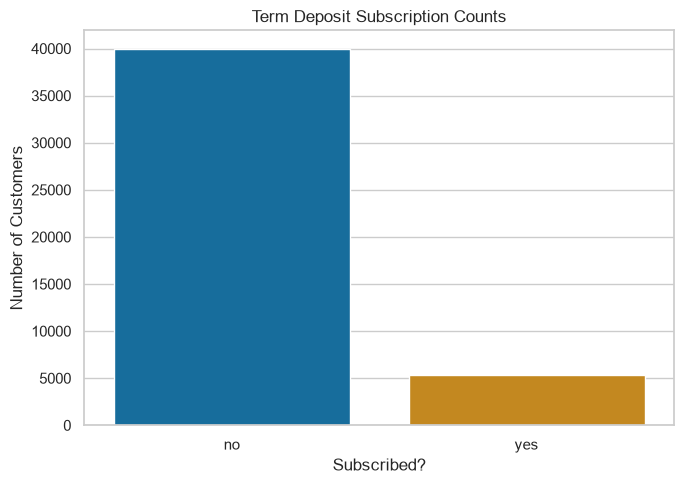

In [8]:
# હવે chart બનાવીએ:
fig, ax = plt.subplots(figsize=(7, 5))

sns.countplot(
    data=df,
    x="y",
    hue="y",
    order=["no", "yes"],
    ax=ax
)

ax.set_title("Term Deposit Subscription Counts")
ax.set_xlabel("Subscribed?")
ax.set_ylabel("Number of Customers")
# ax.legend_.remove()

fig.tight_layout()
fig.savefig("charts/01_subscription_counts.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


In [ ]:
# 7. Step 4 — કયા job group માં subscription rate વધારે છે?
# અહીં માત્ર ગ્રાહકોની સંખ્યા નહીં, પરંતુ દરેક job category માં yes નો ટકાવાર દર કાઢીશું.

job_summary = (
    df.groupby("job", observed=True)["y"] # customers ne job groip ma
      .apply(lambda s: (s == "yes").mean() * 100) # row mate subsciption mean Flae 0 
      .sort_values(ascending=False)
      .reset_index(name="subscription_rate")
)

display(job_summary)

,job,subscription_rate
0,student,28.678038
1,retired,22.791519
2,unemployed,15.502686
3,management,13.755551
4,admin.,12.202669
5,self-employed,11.842939
6,unknown,11.805556
7,technician,11.056996
8,services,8.883004
9,housemaid,8.790323


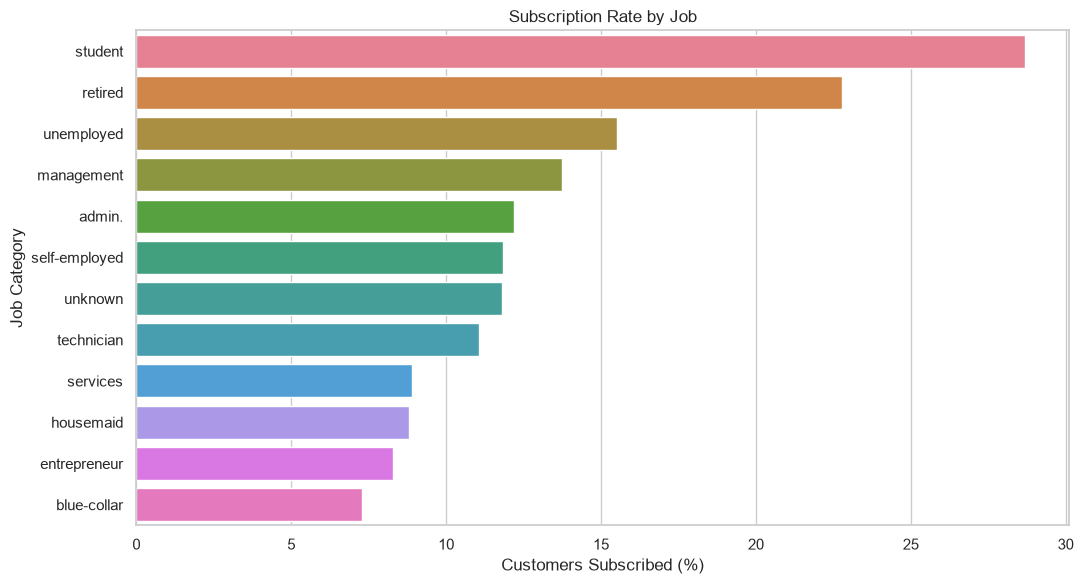

In [10]:
fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=job_summary,
    x="subscription_rate",
    y="job",
    hue="job",
    legend=False,
    errorbar=None,
    ax=ax
)

ax.set_title("Subscription Rate by Job")
ax.set_xlabel("Customers Subscribed (%)")
ax.set_ylabel("Job Category")

fig.tight_layout()
fig.savefig("charts/02_subscription_by_job.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

In [11]:
# Interpretation: આ chart માં જે job category ની bar લાંબી હોય, તેમાં yes નો observed proportion વધારે છે. પરંતુ જો કોઈ category માં customers બહુ ઓછા હોય, તો તેનો rate અસ્થિર હોઈ શકે છે. તેથી rate સાથે group size પણ જોવો.

# Group size તપાસવા માટે:
job_counts = df["job"].value_counts()
display(job_counts)


job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64

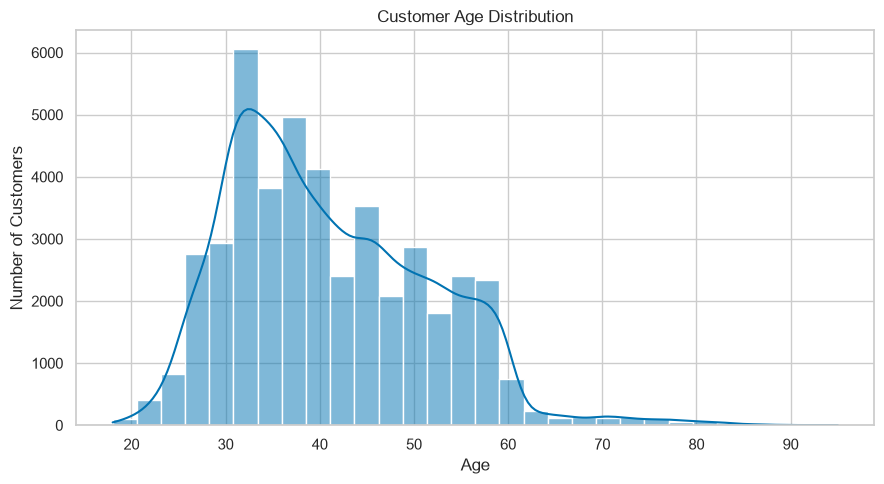

In [ ]:
# 8. Step 5 — Age distribution અને subscription
# ગ્રાહકોની ઉંમરનું distribution જોવા histplot() અને kdeplot() વાપરીએ.

fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=df,
    x="age",
    bins=30,
    kde=True,
    ax=ax
)

ax.set_title("Customer Age Distribution")
ax.set_xlabel("Age")
ax.set_ylabel("Number of Customers")

fig.tight_layout()
fig.savefig("charts/03_age_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ars બતાવે છે કે અલગ age ranges માં કેટલા customers છે.
# KDE curve age distribution નો smoothed અંદાજ આપે છે.
# bins=30 age range ને 30 intervals માં વહેંચે છે.


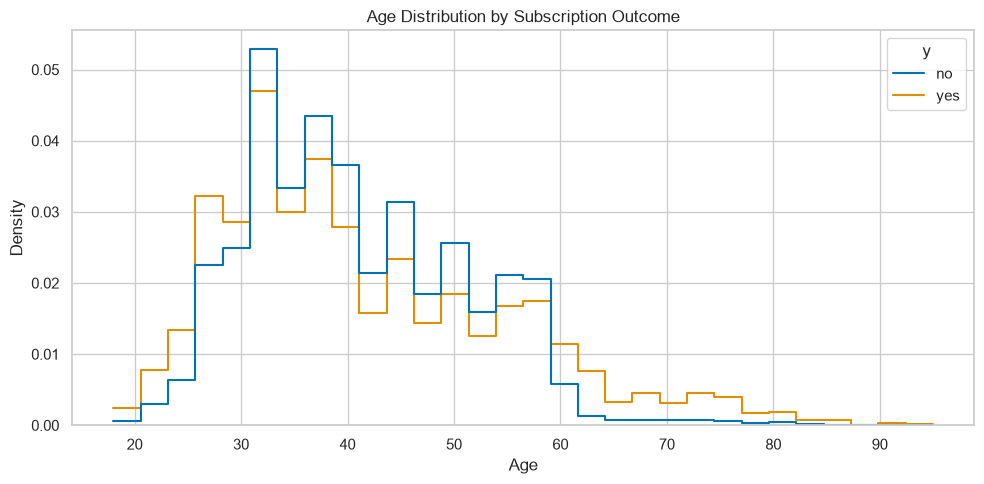

In [13]:
# હવે yes અને no group ની age distribution સરખાવીએ:
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    data=df,
    x="age",
    hue="y",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    ax=ax
)

ax.set_title("Age Distribution by Subscription Outcome")
ax.set_xlabel("Age")
ax.set_ylabel("Density")

fig.tight_layout()
fig.savefig("charts/04_age_by_subscription.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


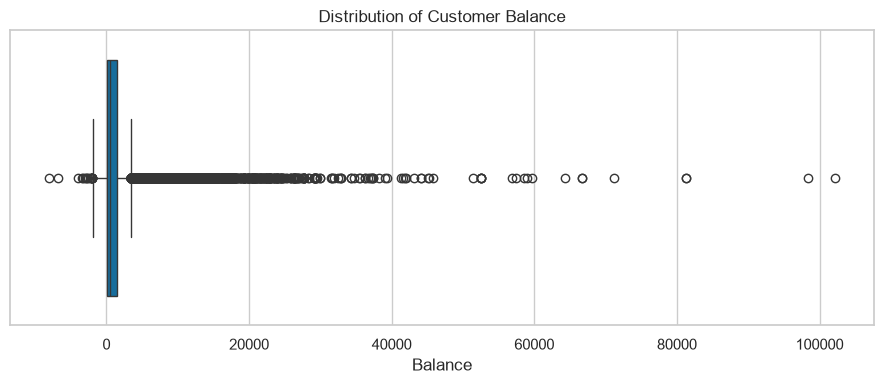

In [14]:
# 9. Step 6 — Balance માં outliers તપાસો
# Bank balance માં negative values પણ હોઈ શકે છે. તે dataset માં દર્શાવેલી સ્થિતિ પ્રમાણે શક્ય છે; તેને આપમેળે કાઢી ન નાખવી.

fig, ax = plt.subplots(figsize=(9, 4))

sns.boxplot(
    data=df,
    x="balance",
    showfliers=True,
    ax=ax
)

ax.set_title("Distribution of Customer Balance")
ax.set_xlabel("Balance")

fig.tight_layout()
fig.savefig("charts/05_balance_boxplot.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

In [15]:
# જો મોટા balance values ના કારણે બાકીની distribution સમજવામાં મુશ્કેલી પડે, તો quantiles તપાસો:
display(df["balance"].quantile([0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1]))


0.00     -8019.0
0.25        72.0
0.50       448.0
0.75      1428.0
0.90      3574.0
0.95      5768.0
0.99     13164.9
1.00    102127.0
Name: balance, dtype: float64

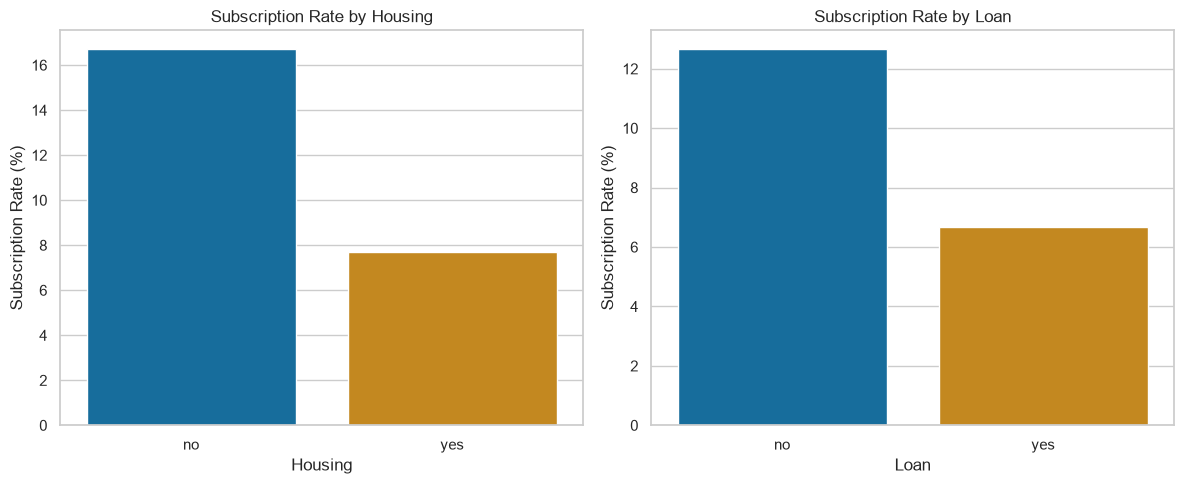

In [ ]:
# 10. Step 7 — Housing loan અને personal loan પ્રમાણે subscription rate
# બેંક એ જાણવા માગે છે કે loan ધરાવતા અને loan ન ધરાવતા ગ્રાહકોના subscription rate માં શું ફરક દેખાય છે.

loan_columns = ["housing", "loan"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, column in zip(axes, loan_columns):
    loan_summary = (
        df.groupby(column, observed=True)["y"]
          .apply(lambda s: (s == "yes").mean() * 100)
          .reset_index(name="subscription_rate")
    )

    sns.barplot(
        data=loan_summary,
        x=column,
        y="subscription_rate",
        hue=column,
        legend=False,
        errorbar=None,
        ax=ax
    )

    ax.set_title(f"Subscription Rate by {column.title()}")
    ax.set_xlabel(column.title())
    ax.set_ylabel("Subscription Rate (%)")

fig.tight_layout()
fig.savefig("charts/06_loan_subscription_rates.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# housing — housing loan ધરાવે છે કે નહીં
# loan — personal loan ધરાવે છે કે નહીં


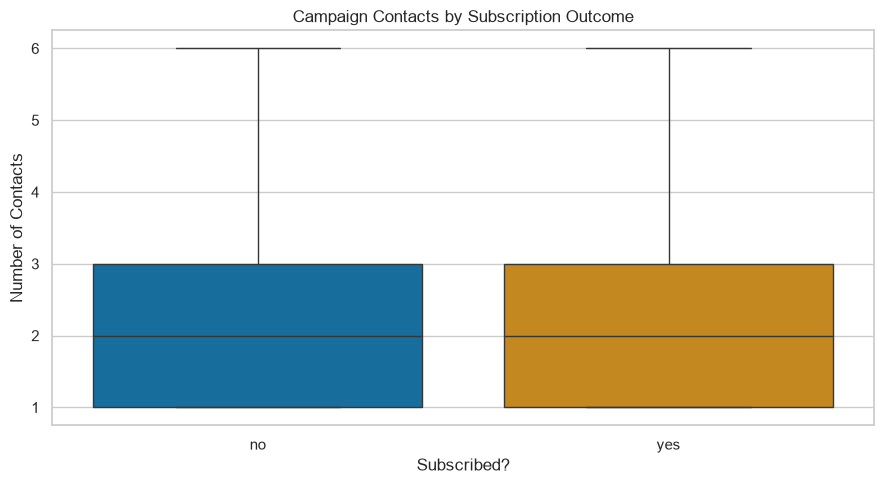

In [17]:
# 11. Step 8 — Campaign દરમિયાન કેટલા contacts થયા?
# campaign column માં આ campaign દરમિયાન એક ગ્રાહકનો કેટલા વખત સંપર્ક થયો તેની સંખ્યા છે; છેલ્લો સંપર્ક પણ તેમાં સામેલ છે
fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="y",
    y="campaign",
    hue="y",
    showfliers=False,
    ax=ax
)

ax.set_title("Campaign Contacts by Subscription Outcome")
ax.set_xlabel("Subscribed?")
ax.set_ylabel("Number of Contacts")

fig.tight_layout()
fig.savefig("charts/07_campaign_contacts.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


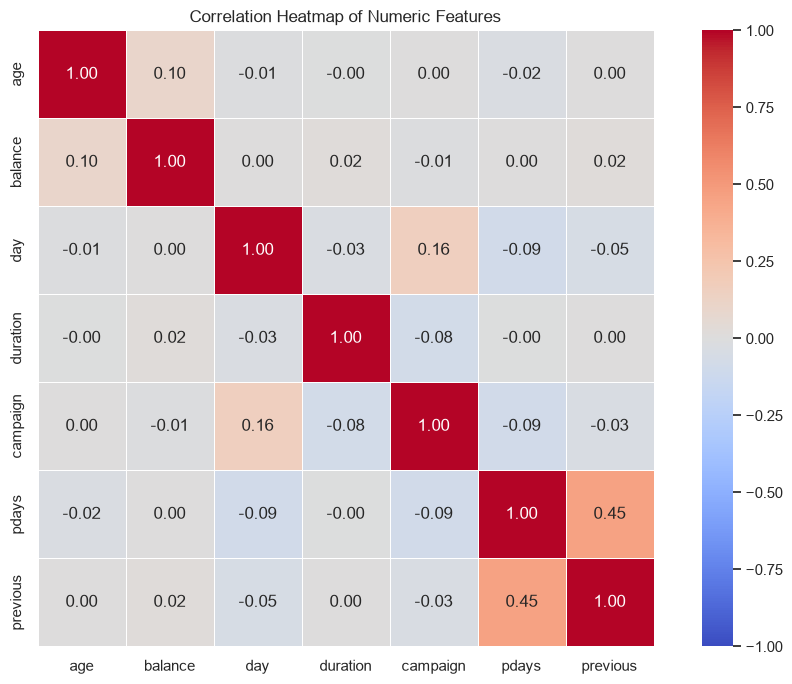

In [ ]:
# 12. Step 9 — Numeric columns નું correlation heatmap
# Correlation matrix વડે numeric columns વચ્ચેના linear relationships નો અંદાજ મેળવી શકીએ છીએ.


numeric_columns = [
    "age",
    "balance",
    "day",
    "duration",
    "campaign",
    "pdays",
    "previous"
]

correlation_matrix = df[numeric_columns].corr()

fig, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    ax=ax
)

ax.set_title("Correlation Heatmap of Numeric Features")

fig.tight_layout()
fig.savefig("charts/08_correlation_heatmap.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Correlation	સામાન્ય અર્થ
# +1 ની નજીક	મજબૂત positive linear relationship
# 0 ની નજીક	નબળો linear relationship
# -1 ની નજીક	મજબૂત negative linear relationship